# 02. Automated Quality Control

## Overview
This notebook implements an automated **Quality Control (QC)** pipeline. Retinal fundus images are often plagued by artifacts (blur, poor illumination, lens caps) that can destabilize model training. 
Instead of manual curation, we calculate a **Quality Score** based on **Vessel Density** (the visibility of retinal blood vessels after preprocessing) to automatically flag ungradable images.

## Objectives
-   Analyze the distribution of vessel density across the dataset (blur image QC)
-   Determine a statistical threshold for rejection (e.g., the 5th percentile).
-   Visually validate the threshold by comparing high-quality vs. low-quality samples.
-   Generate a curated manifest (`manifest_filtered.csv`) for robust model training.

In [7]:
# --- Imports ---
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Add project root
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import PROCESSED_DATA_DIR, QUALITY_THRESHOLD
from src.data.make_dataset import load_filtered_dataset
from src.data.preprocessing import ImagePreprocessor
from src.visualization.eda import load_and_show_quality_examples
from src.visualization.plots import plot_quality_score_distribution, set_plot_style

# --- Configuration ---
set_plot_style()
preprocessor = ImagePreprocessor()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
# 2. Load Manifest
manifest_path = PROCESSED_DATA_DIR / "manifest.csv"

if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print(f"Loaded manifest with {len(df)} images.")

    # Check if scores exist
    if "quality_score" not in df.columns:
        print("\nWARNING: 'quality_score' column missing!")
        print("Please run 'src/scripts/assess_quality.py' to compute scores first.")
    else:
        print("Quality scores found.")
        print(df["quality_score"].describe())
else:
    print("Manifest not found.")

Loaded manifest with 35126 images.
Quality scores found.
count    35126.000000
mean         0.133966
std          0.038480
min          0.000000
25%          0.113641
50%          0.139953
75%          0.160177
max          0.361603
Name: quality_score, dtype: float64


2026-02-17 11:17:49,234 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\quality_score_distribution.png
2026-02-17 11:17:49,234 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\quality_score_distribution.png
2026-02-17 11:17:49,235 - src.visualization.plots - INFO - Suggested Threshold (exclude below): 0.0583
2026-02-17 11:17:49,235 - src.visualization.plots - INFO - Suggested Threshold (exclude below): 0.0583


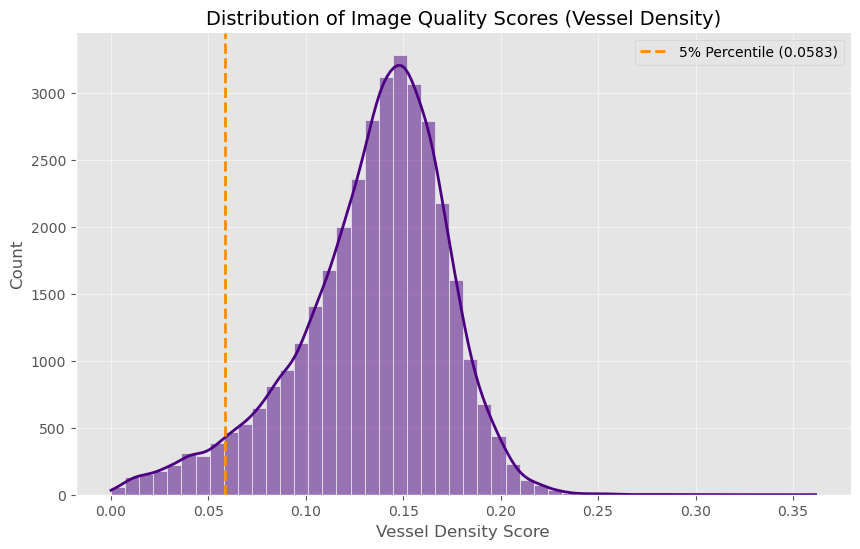

In [9]:
# 3. Distribution of Scores
if "quality_score" in df.columns:
    threshold = plot_quality_score_distribution(df)
    plt.show()

2026-02-17 11:17:49,416 - src.visualization.eda - INFO - Displaying low quality examples...
2026-02-17 11:17:49,416 - src.visualization.eda - INFO - Displaying low quality examples...
2026-02-17 11:17:52,059 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\low_quality_examples_(candidates_for_exclusion).png
2026-02-17 11:17:52,059 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\low_quality_examples_(candidates_for_exclusion).png


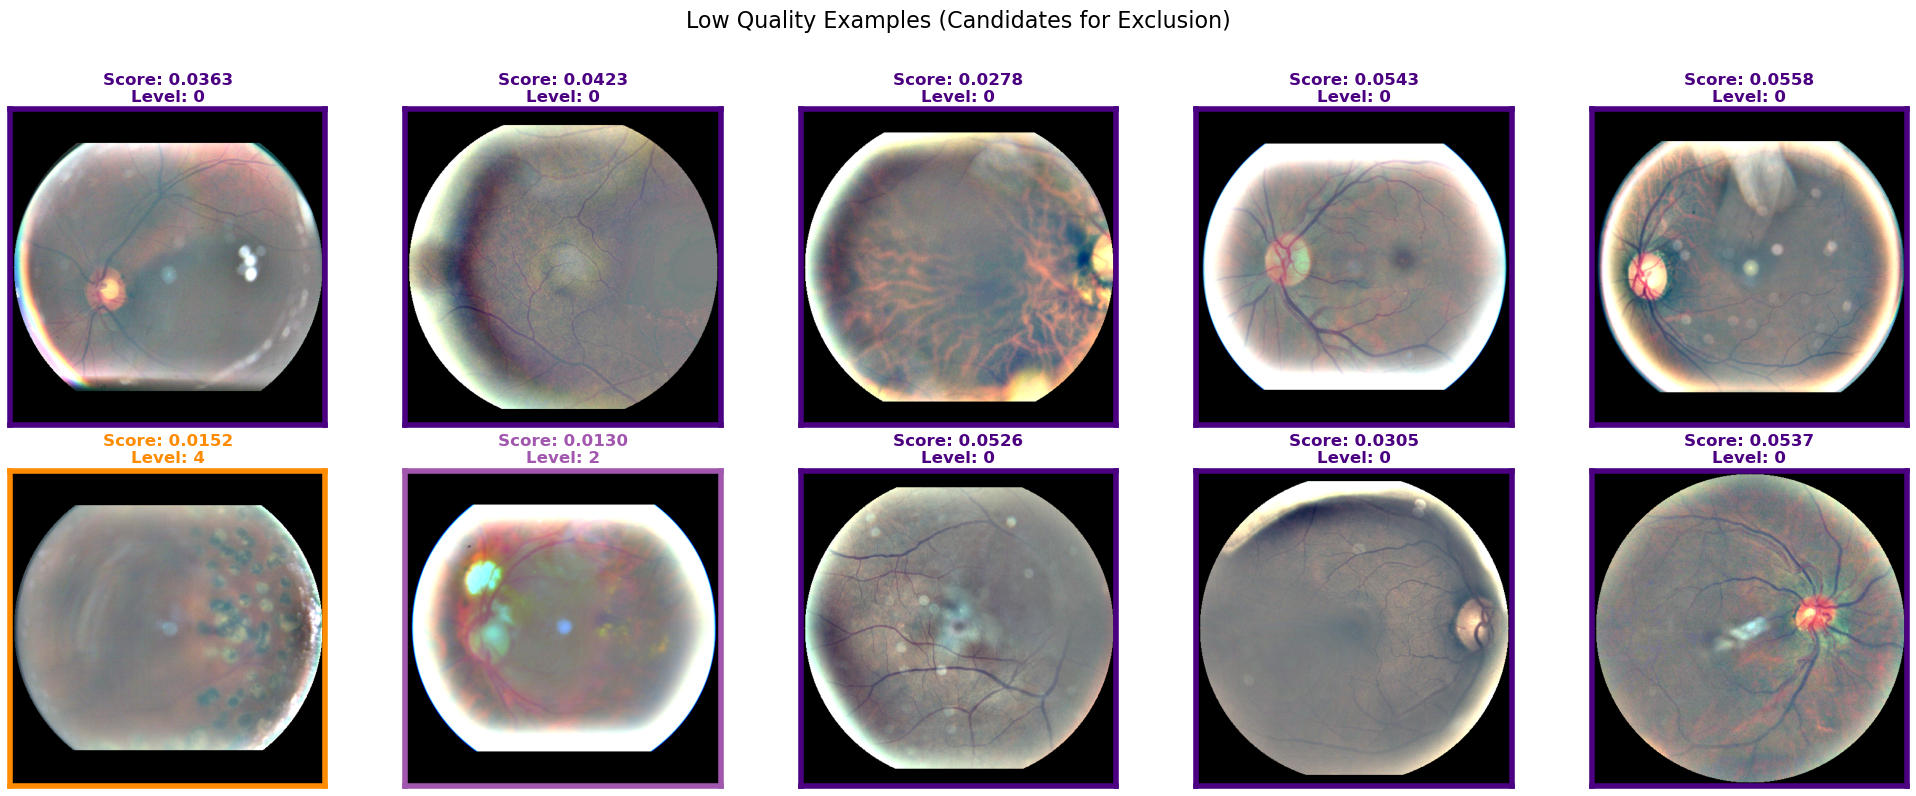

In [10]:
# 4. Visualize Low Quality Examples
if "quality_score" in df.columns:
    load_and_show_quality_examples(df, preprocessor, threshold, quality_type="low")

2026-02-17 11:17:52,410 - src.visualization.eda - INFO - Displaying high quality examples...
2026-02-17 11:17:52,410 - src.visualization.eda - INFO - Displaying high quality examples...
2026-02-17 11:17:54,730 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\high_quality_examples_(clear_vessels_&_good_contrast).png
2026-02-17 11:17:54,730 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\qc\high_quality_examples_(clear_vessels_&_good_contrast).png


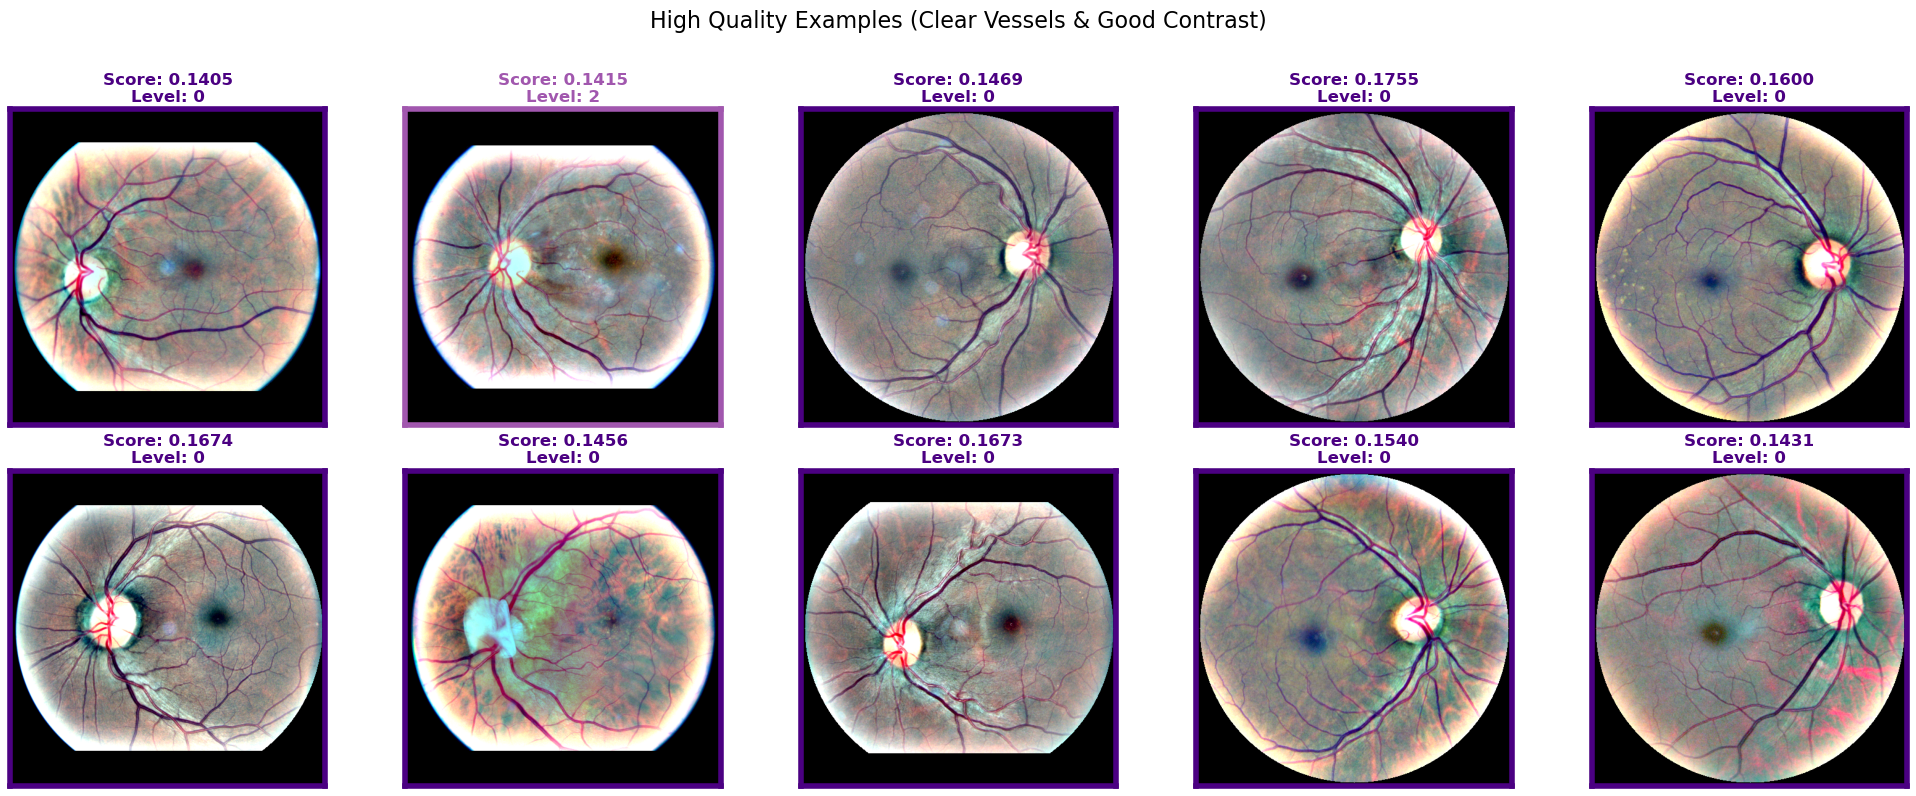

In [11]:
# 4b. Visualize High Quality Examples
if "quality_score" in df.columns:
    load_and_show_quality_examples(df, preprocessor, threshold, quality_type="high")

In [12]:
# 5. Connect to Pipeline Config
# Verify the config threshold matches our analysis.

CHOSEN_THRESHOLD = QUALITY_THRESHOLD

print(f"Configured Quality Threshold: {CHOSEN_THRESHOLD}")

# Verify logic using the loader
df_filtered_test = load_filtered_dataset(manifest_path, min_quality_score=CHOSEN_THRESHOLD)

print("\n--- Verification ---")
print(f"Original Count: {len(df)}")
print(f"Filtered Count: {len(df_filtered_test)}")
print(f"Removed: {len(df) - len(df_filtered_test)} images ({100 * (len(df) - len(df_filtered_test)) / len(df):.1f}%)")

Configured Quality Threshold: 0.0583
2026-02-17 11:17:55,157 - src.data.make_dataset - INFO - Quality Filter: Dropped 1756 images below 0.0583. Remaining: 33370
2026-02-17 11:17:55,157 - src.data.make_dataset - INFO - Quality Filter: Dropped 1756 images below 0.0583. Remaining: 33370

--- Verification ---
Original Count: 35126
Filtered Count: 33370
Removed: 1756 images (5.0%)
